
# Phase A — BILL_AMT1 Experimental Audit

## Objective

Verify the existing SHML experimental results and establish a trustworthy baseline before conducting rigorous missingness and recovery experiments.

## Audit Questions

1. Are the dataset splits correct and reproducible?
2. Does the healthy baseline reproduce the recorded metrics?
3. Is preprocessing fitted exclusively on training data?
4. Why do exploratory and formal experiments report different F1-scores?
5. Were model predictions evaluated before recovery?
6. Are safety decisions calculated from actual metrics?
7. Are the experimental thresholds and random seeds consistent?

## Expected Outcome

A verified experimental configuration, documented discrepancies, and a reliable foundation for subsequent BILL_AMT1 research.


In [3]:
from pathlib import Path
import pandas as pd

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    p for p in (cwd, *cwd.parents)
    if (p / "data" / "working").is_dir()
)

DATA_PATH = (
    PROJECT_ROOT / "data" / "working"
    / "default of credit card clients.xls"
)

df = pd.read_excel(DATA_PATH, header=1, engine="xlrd")

print("Dataset shape:", df.shape)
print("Number of missing values:", df.isna().sum().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())

print("\nBILL_AMT1 summary:")
print(df["BILL_AMT1"].describe())

Dataset shape: (30000, 25)
Number of missing values: 0
Duplicate IDs: 0

BILL_AMT1 summary:
count     30000.000000
mean      51223.330900
std       73635.860576
min     -165580.000000
25%        3558.750000
50%       22381.500000
75%       67091.000000
max      964511.000000
Name: BILL_AMT1, dtype: float64


Three important observations:
1. The mean is substantially higher than the median. This suggests the feature is right-skewed, potentially influenced by large billing amounts.
2. Negative billing amounts exist. They should not automatically be treated as errors; they may represent credits or adjustments.
3. The full-dataset median is 22,381.50. Our previous SHML pipeline used a training-set median of 22,225.50. This is not necessarily a discrepancy: training-only statistics differ from full-dataset statistics, and using the training median helps prevent data leakage.


## Step 2 — Data Splitting Verification

Reproduce the original stratified train/validation/test
split using random seed 42.

Verify that the resulting datasets contain the expected
number of observations and preserve the target distribution.


In [5]:
from sklearn.model_selection import train_test_split

TARGET = "default payment next month"
X = df.drop(columns = ["ID", TARGET])
y = df[TARGET]

# Original training split: 70%
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

print("\nTarget class distribution:")
for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(name, target.value_counts(normalize=True).round(4).to_dict())

print("\nTraining BILL_AMT1 median:",
      X_train["BILL_AMT1"].median())

assert len(X_train) == 21000
assert len(X_val) == 4500
assert len(X_test) == 4500

print("\nDataset split verification passed!")


Training observations: 21000
Validation observations: 4500
Testing observations: 4500

Target class distribution:
Train {0: 0.7788, 1: 0.2212}
Validation {0: 0.7789, 1: 0.2211}
Test {0: 0.7787, 1: 0.2213}

Training BILL_AMT1 median: 22225.5

Dataset split verification passed!



## Step 3 — Healthy Baseline Reproduction

Objective:
Reproduce the existing Logistic Regression baseline using
the verified dataset split and training-only preprocessing.

This establishes the reference performance against which
future corruption and recovery experiments will be compared.


In [6]:

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Fit preprocessing on training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# 2. Train the original baseline model
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

# 3. Generate validation predictions
y_val_pred = baseline_model.predict(X_val_scaled)
y_val_proba = baseline_model.predict_proba(
    X_val_scaled
)[:, 1]

# 4. Calculate evaluation metrics
baseline_metrics = {
    "accuracy": accuracy_score(y_val, y_val_pred),
    "precision": precision_score(y_val, y_val_pred),
    "recall": recall_score(y_val, y_val_pred),
    "f1": f1_score(y_val, y_val_pred),
    "roc_auc": roc_auc_score(y_val, y_val_proba)
}

# 5. Compare against recorded baseline
expected_metrics = {
    "accuracy": 0.8087,
    "precision": 0.6948,
    "recall": 0.2402,
    "f1": 0.3570,
    "roc_auc": 0.7130
}

comparison = pd.DataFrame({
    "Recorded": expected_metrics,
    "Reproduced": baseline_metrics
})

comparison["Difference"] = (
    comparison["Reproduced"] - comparison["Recorded"]
)

print("Healthy baseline comparison:")
display(comparison.round(6))

print("\nClassification threshold: 0.50")

# 6. Check numerical agreement
for metric, expected in expected_metrics.items():
    assert abs(baseline_metrics[metric] - expected) < 0.0001, (
        f"Baseline mismatch for {metric}"
    )

print("\nHealthy baseline reproduction passed!")


Healthy baseline comparison:


,Recorded,Reproduced,Difference
accuracy,0.8087,0.808667,-0.000033
precision,0.6948,0.694767,-0.000033
recall,0.2402,0.240201,0.000001
f1,0.3570,0.356983,-0.000017
roc_auc,0.7130,0.713025,0.000025



Classification threshold: 0.50

Healthy baseline reproduction passed!



### Baseline Audit Conclusion

The dataset integrity, stratified data splitting, and healthy
Logistic Regression baseline were successfully verified.

All five performance metrics reproduced the recorded values
within a tolerance of 0.0001.

Baseline F1-score: 0.356983
Baseline recall: 0.240201
Training BILL_AMT1 median: 22225.5

The baseline is reproducible under the tested configuration.

The remaining research must determine whether controlled
BILL_AMT1 missingness causes predictive degradation and
whether recovery improves performance.



# Phase B — BILL_AMT1 Feature Analysis

## Research Objective

Investigate the statistical properties and predictive
contribution of BILL_AMT1 to understand the model's
apparent resilience to controlled missingness.

## Research Questions

1. What is the distribution of BILL_AMT1?
2. How strongly is BILL_AMT1 associated with other
   billing amount features?
3. How does BILL_AMT1 influence model predictions?
4. Does feature redundancy help explain why the
   model's F1-score remains relatively stable
   after median imputation?

## Related Hypothesis

H4: Missingness severity affects predictive performance
and recovery effectiveness, while information retained
in related predictors may reduce degradation.


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Project paths
cwd = Path.cwd().resolve()
relative_path = Path("data/working/default of credit card clients.xls")

PROJECT_ROOT = next(
    (p for p in (cwd, *cwd.parents) if (p / relative_path).is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not find {relative_path} from {cwd} or its parent directories."
    )

DATA_PATH = PROJECT_ROOT / relative_path

# Load data
df = pd.read_excel(DATA_PATH, header=1, engine="xlrd")

TARGET = "default payment next month"

X = df.drop(columns=["ID", TARGET])
y = df[TARGET]

# Split data: 70% training, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42,
)

# Fit the scaler using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train baseline model
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
)
baseline_model.fit(X_train_scaled, y_train)

print("Existing experimental configuration loaded.")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("BILL_AMT1 training median:", X_train["BILL_AMT1"].median())

Existing experimental configuration loaded.
Training samples: 21000
Validation samples: 4500
BILL_AMT1 training median: 22225.5


BILL_AMT1 distribution summary:
count     21000.000000
mean      51194.218810
std       73633.982306
min     -165580.000000
25%        3509.750000
50%       22225.500000
75%       67062.750000
max      964511.000000
Name: BILL_AMT1, dtype: float64

Skewness: 2.6656
Negative values: 412
Zero values: 1399


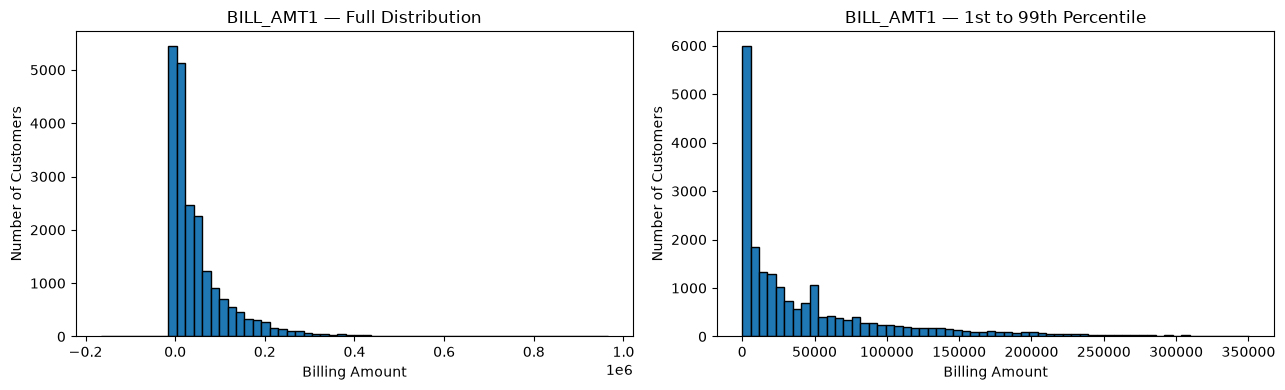

In [10]:

bill = X_train["BILL_AMT1"]

print("BILL_AMT1 distribution summary:")
print(bill.describe())

print("\nSkewness:", round(bill.skew(), 4))
print("Negative values:", (bill < 0).sum())
print("Zero values:", (bill == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Full distribution
axes[0].hist(bill, bins=60, edgecolor="black")
axes[0].set_title("BILL_AMT1 — Full Distribution")
axes[0].set_xlabel("Billing Amount")
axes[0].set_ylabel("Number of Customers")

# Central 98% for easier interpretation
lower = bill.quantile(0.01)
upper = bill.quantile(0.99)

axes[1].hist(
    bill[(bill >= lower) & (bill <= upper)],
    bins=60,
    edgecolor="black"
)
axes[1].set_title("BILL_AMT1 — 1st to 99th Percentile")
axes[1].set_xlabel("Billing Amount")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()



### Observation B.1 — BILL_AMT1 Distribution

The training distribution of BILL_AMT1 is strongly
right-skewed (skewness = 2.6656).

The mean (51,194.22) substantially exceeds the median
(22,225.50), indicating the influence of large positive
billing amounts.

Of the 21,000 training observations, 412 (1.96%) contain
negative values and 1,399 (6.66%) contain zero values.

These findings motivate comparing median imputation
with alternative recovery strategies.

However, distributional skewness alone does not establish
that median imputation provides superior predictive recovery.


BILL_AMT1 correlations:
BILL_AMT1    1.0000
BILL_AMT2    0.9525
BILL_AMT3    0.9005
BILL_AMT4    0.8635
BILL_AMT5    0.8341
BILL_AMT6    0.8076
Name: BILL_AMT1, dtype: float64


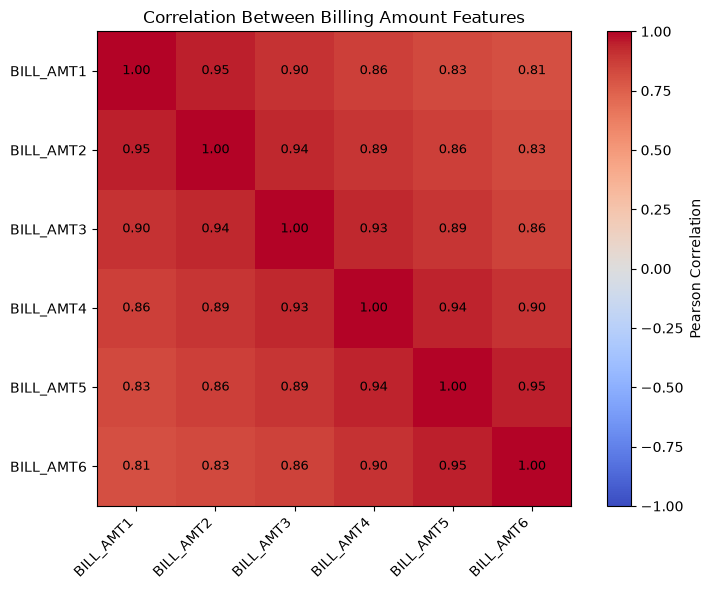

In [11]:

# Phase B — Step 4: Feature Correlation Analysis

import matplotlib.pyplot as plt

bill_features = [
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6"
]

# Use training data only
bill_df = X_train[bill_features]

# Calculate Pearson correlation
correlation_matrix = bill_df.corr(method="pearson")

print("BILL_AMT1 correlations:")
print(
    correlation_matrix["BILL_AMT1"]
    .sort_values(ascending=False)
    .round(4)
)

# Create correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(bill_features)))
ax.set_yticks(range(len(bill_features)))

ax.set_xticklabels(bill_features, rotation=45, ha="right")
ax.set_yticklabels(bill_features)

# Add correlation values inside cells
for i in range(len(bill_features)):
    for j in range(len(bill_features)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

ax.set_title("Correlation Between Billing Amount Features")
fig.colorbar(im, ax=ax, label="Pearson Correlation")

plt.tight_layout()
plt.show()



### Observation B.2 — Feature Correlation

BILL_AMT1 demonstrates strong positive correlations
with the other billing amount predictors.

The strongest association is with BILL_AMT2
(r = 0.9525), followed by BILL_AMT3 (r = 0.9005).

These findings suggest substantial shared information
among consecutive billing amount features.

Feature redundancy may contribute to the model's
apparent resilience to BILL_AMT1 missingness.

However, correlation alone does not establish
predictive substitutability or demonstrate recovery
effectiveness.

Further model-sensitivity experiments are required.


Top 10 features by absolute coefficient:


,Feature,Coefficient,Absolute_Coefficient,Rank
0,PAY_0,0.653654,0.653654,1
1,BILL_AMT1,-0.312812,0.312812,2
2,PAY_AMT2,-0.253532,0.253532,3
3,PAY_AMT1,-0.152160,0.152160,4
4,LIMIT_BAL,-0.116704,0.116704,5
5,BILL_AMT3,0.106742,0.106742,6
6,PAY_2,0.104018,0.104018,7
7,EDUCATION,-0.096321,0.096321,8
8,PAY_3,0.086926,0.086926,9
9,MARRIAGE,-0.078764,0.078764,10



BILL_AMT1 coefficient and rank:


,Feature,Coefficient,Absolute_Coefficient,Rank
1,BILL_AMT1,-0.312812,0.312812,2


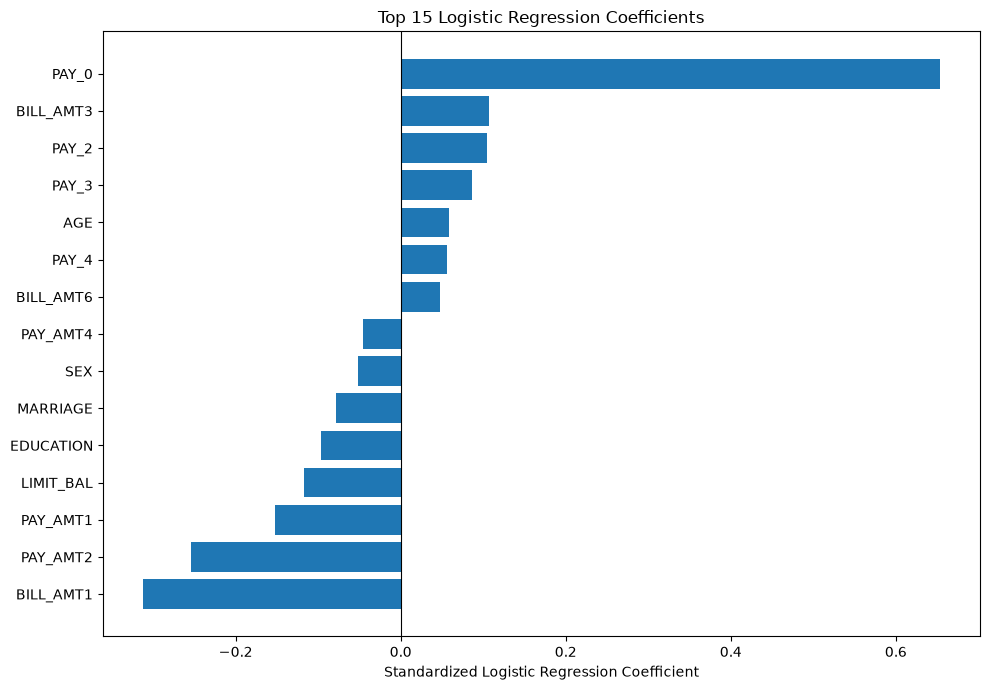

In [12]:

# Phase B — Step 5: Model Coefficient Analysis

# Use the existing baseline_model and X_train
# No retraining is necessary.

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": baseline_model.coef_[0]
})

coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

coef_df["Rank"] = np.arange(1, len(coef_df) + 1)

print("Top 10 features by absolute coefficient:")
display(coef_df.head(10))

print("\nBILL_AMT1 coefficient and rank:")
display(
    coef_df[coef_df["Feature"] == "BILL_AMT1"]
)

# Plot the 15 largest absolute coefficients
top_features = coef_df.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Standardized Logistic Regression Coefficient")
plt.title("Top 15 Logistic Regression Coefficients")

plt.tight_layout()
plt.show()



### Observation B.3 — Logistic Regression Coefficients

BILL_AMT1 has a standardized Logistic Regression
coefficient of -0.312812 and ranks second among
23 predictors by absolute coefficient magnitude.

Its negative coefficient indicates a negative
conditional association with predicted default
log-odds when other model features are held fixed.

However, BILL_AMT1 is strongly correlated with
the other billing amount features, particularly
BILL_AMT2 (r = 0.9525).

Because of multicollinearity, coefficient magnitude
alone cannot establish predictive importance.

The next experiment will directly measure how
BILL_AMT1 perturbations change model predictions
and classification performance.


In [13]:

# Phase B — Step 6: BILL_AMT1 Prediction Sensitivity

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Healthy validation data
X_healthy = X_val.copy(deep=True)

# Controlled intervention:
# Replace BILL_AMT1 for every validation observation
X_modified = X_val.copy(deep=True)

training_median = X_train["BILL_AMT1"].median()
X_modified["BILL_AMT1"] = training_median

# Apply the existing training-fitted scaler
healthy_scaled = scaler.transform(X_healthy)
modified_scaled = scaler.transform(X_modified)

# Generate predictions with the SAME baseline model
healthy_proba = baseline_model.predict_proba(
    healthy_scaled
)[:, 1]

modified_proba = baseline_model.predict_proba(
    modified_scaled
)[:, 1]

# Same classification threshold
threshold = 0.50

healthy_pred = (healthy_proba >= threshold).astype(int)
modified_pred = (modified_proba >= threshold).astype(int)

def calculate_metrics(y_true, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions,
                                     zero_division=0),
        "Recall": recall_score(y_true, predictions,
                              zero_division=0),
        "F1": f1_score(y_true, predictions,
                       zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

healthy_metrics = calculate_metrics(
    y_val, healthy_pred, healthy_proba
)

modified_metrics = calculate_metrics(
    y_val, modified_pred, modified_proba
)

comparison = pd.DataFrame({
    "Healthy": healthy_metrics,
    "BILL_AMT1 replaced": modified_metrics
})

comparison["Difference"] = (
    comparison["BILL_AMT1 replaced"] -
    comparison["Healthy"]
)

print("Prediction sensitivity comparison:")
display(comparison.round(6))

# Measure individual prediction changes
prediction_changes = np.sum(
    healthy_pred != modified_pred
)

mean_probability_change = np.mean(
    np.abs(healthy_proba - modified_proba)
)

print("\nChanged class predictions:", prediction_changes)
print("Percentage changed:",
      round(100 * prediction_changes / len(y_val), 2), "%")

print("Mean absolute probability change:",
      round(mean_probability_change, 6))


Prediction sensitivity comparison:


,Healthy,BILL_AMT1 replaced,Difference
Accuracy,0.808667,0.810000,0.001333
Precision,0.694767,0.665094,-0.029673
Recall,0.240201,0.283417,0.043216
F1,0.356983,0.397463,0.040480
ROC-AUC,0.713025,0.701094,-0.011932



Changed class predictions: 94
Percentage changed: 2.09 %
Mean absolute probability change: 0.029674



### Observation B.4 — Prediction Sensitivity

A controlled sensitivity experiment replaced all
BILL_AMT1 values in the validation dataset with the
training median (22,225.5).

The experiment produced the following results:

- Validation observations: 4,500
- Changed classification decisions: 94
- Classification change rate: 2.09%
- Mean absolute probability change: 0.029674

The results indicate that the trained Logistic
Regression model is relatively stable at the
classification-decision level under complete
median replacement of BILL_AMT1.

However, predicted probabilities do change,
demonstrating that BILL_AMT1 influences model outputs.

Strong correlations with other billing features
provide a possible explanation for this stability,
but the causal role of feature redundancy remains
unverified.

This experiment evaluates prediction sensitivity,
not automated recovery effectiveness.


In [14]:
display(comparison.round(6))

,Healthy,BILL_AMT1 replaced,Difference
Accuracy,0.808667,0.810000,0.001333
Precision,0.694767,0.665094,-0.029673
Recall,0.240201,0.283417,0.043216
F1,0.356983,0.397463,0.040480
ROC-AUC,0.713025,0.701094,-0.011932



### Observation B.5 — Performance Sensitivity

Replacing 100% of BILL_AMT1 validation values with the
training median increased F1 from 0.356983 to 0.397463
and recall from 0.240201 to 0.283417.

However, precision decreased from 0.694767 to 0.665094,
and ROC-AUC decreased from 0.713025 to 0.701094.

Only 94 of 4,500 classification decisions changed (2.09%).
The mean absolute predicted-probability change was 0.029674.

These results demonstrate that complete median replacement
affects classification performance differently across metrics.

The improvement in F1 does not establish successful recovery
because the experiment did not begin with an independently
measured, degraded untreated condition.

The findings also suggest that classification-threshold
sensitivity may contribute to the observed behavior.

Feature redundancy remains a plausible but unverified
explanation for prediction stability.


,Threshold,Healthy_F1,Modified_F1,Healthy_Recall,Modified_Recall,F1_Difference
0,0.10,0.3846,0.3842,0.9005,0.9065,-0.0005
1,0.15,0.3993,0.3841,0.7839,0.8070,-0.0152
2,0.20,0.4380,0.4007,0.6884,0.7568,-0.0372
3,0.25,0.5052,0.4515,0.5638,0.5970,-0.0536
4,0.30,0.5028,0.4946,0.4533,0.4643,-0.0081
5,0.35,0.4827,0.4933,0.4060,0.4281,0.0107
6,0.40,0.4698,0.4888,0.3719,0.4070,0.0190
7,0.45,0.4277,0.4595,0.3136,0.3568,0.0319
8,0.50,0.3570,0.3975,0.2402,0.2834,0.0405
9,0.55,0.3171,0.3512,0.2000,0.2332,0.0341


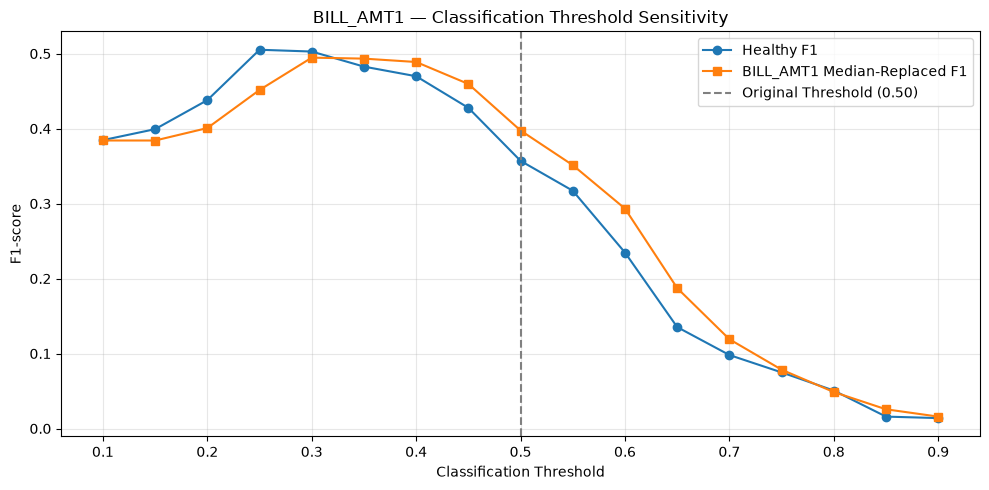

In [15]:

# Phase B — Step 7: Classification Threshold Sensitivity

from sklearn.metrics import f1_score, recall_score

thresholds = np.arange(0.10, 0.91, 0.05)
results = []

for t in thresholds:
    healthy_predictions = (healthy_proba >= t).astype(int)
    modified_predictions = (modified_proba >= t).astype(int)

    results.append({
        "Threshold": round(t, 2),
        "Healthy_F1": f1_score(y_val, healthy_predictions),
        "Modified_F1": f1_score(y_val, modified_predictions),
        "Healthy_Recall": recall_score(y_val, healthy_predictions),
        "Modified_Recall": recall_score(y_val, modified_predictions)
    })

threshold_df = pd.DataFrame(results)

threshold_df["F1_Difference"] = (
    threshold_df["Modified_F1"] - threshold_df["Healthy_F1"]
)

display(threshold_df.round(4))

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Healthy_F1"],
    marker="o",
    label="Healthy F1"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Modified_F1"],
    marker="s",
    label="BILL_AMT1 Median-Replaced F1"
)

plt.axvline(
    0.50,
    color="gray",
    linestyle="--",
    label="Original Threshold (0.50)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("F1-score")
plt.title("BILL_AMT1 — Classification Threshold Sensitivity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Observation B.6 — Threshold Sensitivity

The effect of complete BILL_AMT1 median replacement
on F1-score depends on the classification threshold.

At the original threshold of 0.50:
- Healthy F1: 0.356983
- Median-replaced F1: 0.397463

However, at a threshold of 0.25:
- Healthy F1: 0.5052
- Median-replaced F1: 0.4515

The healthy model achieved a higher maximum F1
across the evaluated threshold grid.

These findings suggest that the apparent improvement
after median replacement is partly associated with
classification-threshold sensitivity.

The original 0.50 threshold will remain fixed for
the primary controlled recovery experiments to
preserve comparability with the existing SHML pipeline.

Threshold optimization remains a separate
experimental question and must avoid test-set leakage.
